In [98]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error ,r2_score
from sklearn.model_selection import train_test_split
import seaborn as sns
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt


In [21]:
#Load dataset
insurance_dataset=pd.read_csv("data//insurance.csv")

#features
X = insurance_dataset.drop(columns=["charges"])  # Input features
Y = insurance_dataset["charges"] # Output feature

# mapping &  one hot encoding
X=pd.get_dummies(
                 X,
                 columns=["region"],
                 drop_first=True,
                 dtype=int
                 )

X["sex"]=X["sex"].map({
    "female":1,
    "male":0
               }
               )
X["smoker"]=X["smoker"].map({
    "yes":1,
    "no":0   
})

#spliting
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42)

# Applying Lasso Regression

MSE Values alpha = 0.1 33597770.05720262
MSE Values alpha = 0.2 33598625.50374359
MSE Values alpha = 0.3 33599483.28354537
MSE Values alpha = 0.4 33600339.87102707
MSE Values alpha = 0.5 33601197.56637194
MSE Values alpha = 0.6 33602056.36957996
MSE Values alpha = 0.7 33602921.20016722
MSE Values alpha = 0.8 33603782.21752162
MSE Values alpha = 0.9 33604644.342647895
MSE Values alpha = 1.0 33605507.57554603
MSE Values alpha = 2 33614211.308740854
MSE Values alpha = 3 33623037.56043786
MSE Values alpha = 4 33631952.08146762
MSE Values alpha = 5 33639750.859859034


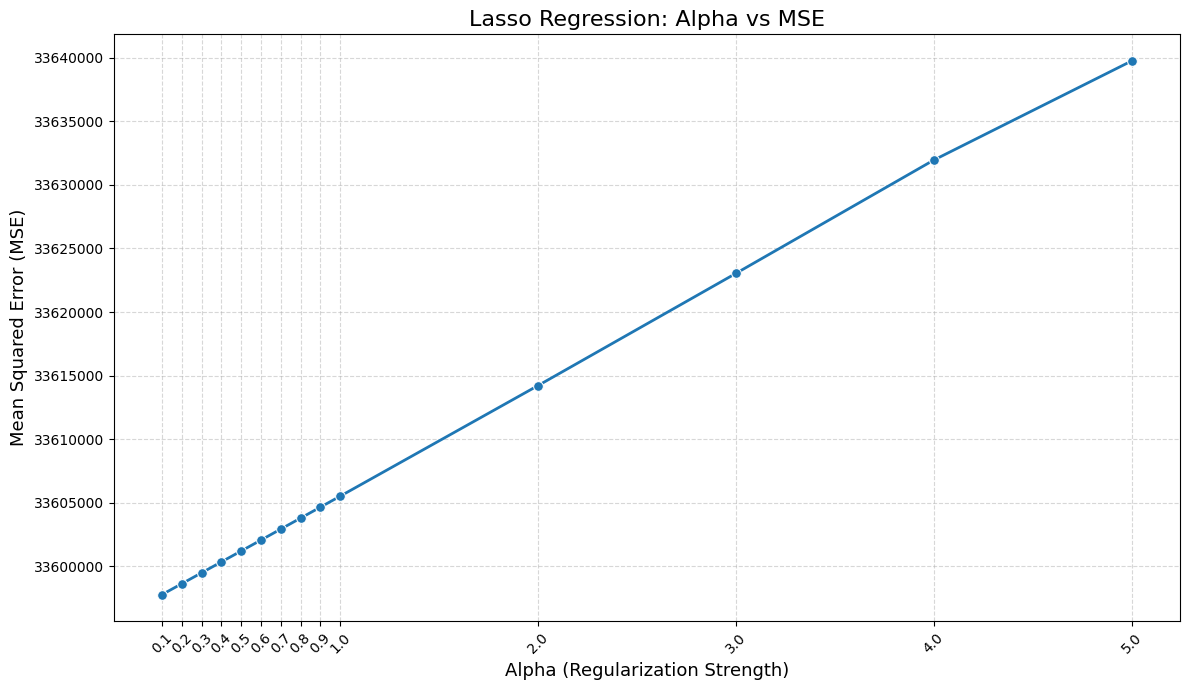

In [69]:
alphas= [0.1, 0.2, 0.3, 0.4, 0.5,
          0.6, 0.7, 0.8, 0.9, 1.0,
          2, 3, 4, 5]
mse=[]

for a in alphas:
    Lasso_model = Lasso(alpha=a)
    Lasso_model.fit(X_train,y_train)
    
    y_pred = Lasso_model.predict(X_test)
    error = mean_squared_error(y_test, y_pred)

    mse.append(error)
    print(f"MSE Values alpha = {a}",error )


plt.figure(figsize=(12, 7))

ax = sns.lineplot(
    x=alphas,
    y=mse,
    marker="o",
    markersize=7,
    linewidth=2
)

# Axis labels
plt.xlabel("Alpha (Regularization Strength)", fontsize=13)
plt.ylabel("Mean Squared Error (MSE)", fontsize=13)

# Title
plt.title("Lasso Regression: Alpha vs MSE", fontsize=16)

# Show all alpha values on X-axis
plt.xticks(alphas, rotation=45)

# Display more ticks on Y-axis
ax.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Avoid scientific notation on Y-axis
ax.ticklabel_format(axis="y", style="plain", useOffset=False)

# Grid
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()



# Using LassoCV method(Cross Validation)

In [99]:
from sklearn.linear_model import LassoCV
a=np.logspace(-4,3,100)

Lasso_CV_model=LassoCV(
    alphas=a,
    cv=5,
    max_iter=10000,
    random_state=42
)

Lasso_CV_model.fit(X_train,y_train)
print("best alpha value ",Lasso_CV_model.alpha_)

y_pred = Lasso_CV_model.predict(X_test)
error = mean_squared_error(y_test, y_pred)
print(f"MSE Values alpha ",error )

r2=r2_score(y_pred,y_test)
print("R2 SCORE ",r2)

best alpha value  86.97490026177834
MSE Values alpha  34202010.06824254
R2 SCORE  0.6918263330977401
